In [78]:


import pandas as pd

import seaborn as sb
import matplotlib.pyplot as plt
import numpy as np

In [79]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "valakhorasani/gym-members-exercise-dataset",
    "gym_members_exercise_tracking.csv"
)

df.head()

/var/folders/28/tt6vttm91r1c29lt4s1fr9z40000gn/T/ipykernel_1148/4284422673.py:4: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,Female,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71
3,25,Male,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,Male,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39


In [80]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    str    
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Workout_Type                   973 non-null    str    
 10  Fat_Percentage                 973 non-null    float64
 11  Water_Intake (liters)          973 non-null    float64
 12  Workout_Frequency (days/week)  973 non-null    int64  
 13  E

In [81]:
df.describe()

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,973.000000,973.000000,973.00000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000
mean,38.683453,73.854676,1.72258,179.883864,143.766701,62.223022,1.256423,905.422405,24.976773,2.626619,3.321686,1.809866,24.912127
std,12.180928,21.207500,0.12772,11.525686,14.345101,7.327060,0.343033,272.641516,6.259419,0.600172,0.913047,0.739693,6.660879
min,18.000000,40.000000,1.50000,160.000000,120.000000,50.000000,0.500000,303.000000,10.000000,1.500000,2.000000,1.000000,12.320000
25%,28.000000,58.100000,1.62000,170.000000,131.000000,56.000000,1.040000,720.000000,21.300000,2.200000,3.000000,1.000000,20.110000
50%,40.000000,70.000000,1.71000,180.000000,143.000000,62.000000,1.260000,893.000000,26.200000,2.600000,3.000000,2.000000,24.160000
75%,49.000000,86.000000,1.80000,190.000000,156.000000,68.000000,1.460000,1076.000000,29.300000,3.100000,4.000000,2.000000,28.560000
max,59.000000,129.900000,2.00000,199.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,49.840000


In [82]:
df['Calories_Burned'].mean()

np.float64(905.4224049331963)

In [83]:
print(df['Gender'].value_counts())
print()
print(df['Workout_Type'].value_counts())

Gender
Male      511
Female    462
Name: count, dtype: int64

Workout_Type
Strength    258
Cardio      255
Yoga        239
HIIT        221
Name: count, dtype: int64


In [84]:
male_strength = df[
    (df['Gender'] == 'Male') &
    (df['Workout_Type'] == 'Strength')
].copy()

female_strength = df[
    (df['Gender'] == 'Female') &
    (df['Workout_Type'] == 'Strength')
].copy()

male_cardio = df[
    (df['Gender'] == 'Male') &
    (df['Workout_Type'] == 'Cardio')
].copy()

female_cardio = df[
    (df['Gender'] == 'Female') &
    (df['Workout_Type'] == 'Cardio')
].copy()

In [85]:
print("Male Strength:", len(male_strength))
print("Female Strength:", len(female_strength))
print("Male Cardio:", len(male_cardio))
print("Female Cardio:", len(female_cardio))


Male Strength: 135
Female Strength: 123
Male Cardio: 129
Female Cardio: 126


In [86]:
features = [
    'Age',
    'Weight (kg)',
    'Height (m)',
    'Max_BPM',
    'Avg_BPM',
    'Resting_BPM',
    'Session_Duration (hours)',
    'Fat_Percentage',
    'Water_Intake (liters)',
    'Workout_Frequency (days/week)',
    'Experience_Level'
]

X = df[features].copy()

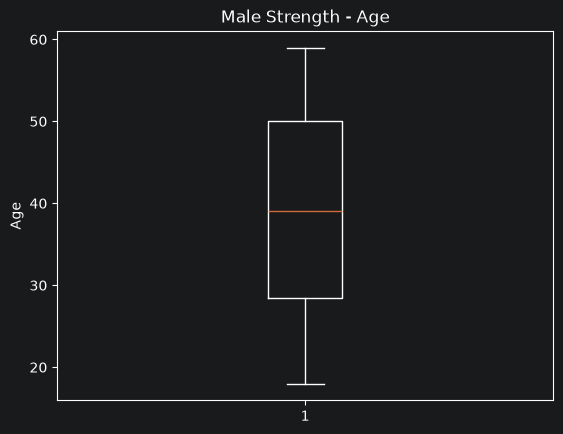

count    135.000000
mean      39.148148
std       11.935472
min       18.000000
25%       28.500000
50%       39.000000
75%       50.000000
max       59.000000
Name: Age, dtype: float64

In [87]:
#PROVERA ZA OUTLEIRE

plt.boxplot(male_strength['Age'])
plt.title('Male Strength - Age')
plt.ylabel('Age')
plt.show()

male_strength['Age'].describe()

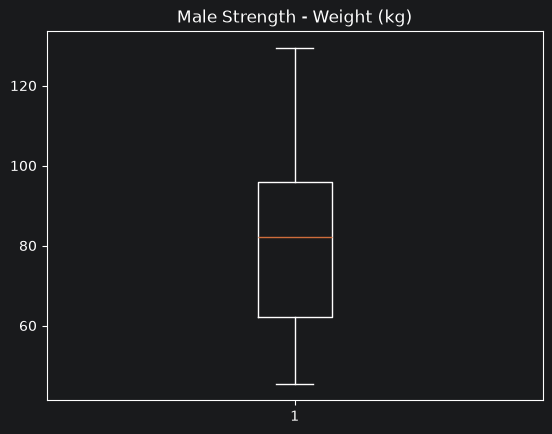

In [88]:
plt.boxplot(male_strength['Weight (kg)'])
plt.title('Male Strength - Weight (kg)')
plt.show()

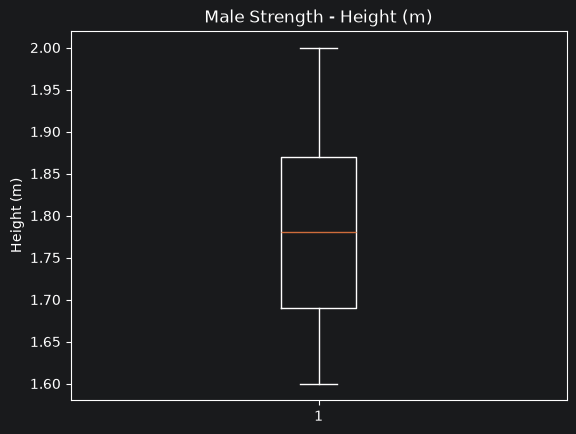

In [89]:
plt.boxplot(male_strength['Height (m)'])
plt.title('Male Strength - Height (m)')
plt.ylabel('Height (m)')
plt.show()

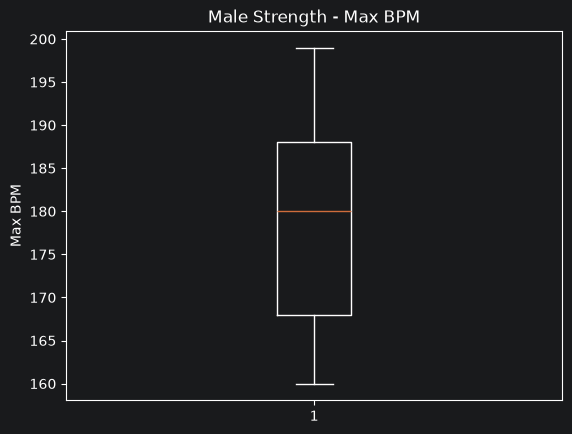

In [90]:
plt.boxplot(male_strength['Max_BPM'])
plt.title('Male Strength - Max BPM')
plt.ylabel('Max BPM')
plt.show()

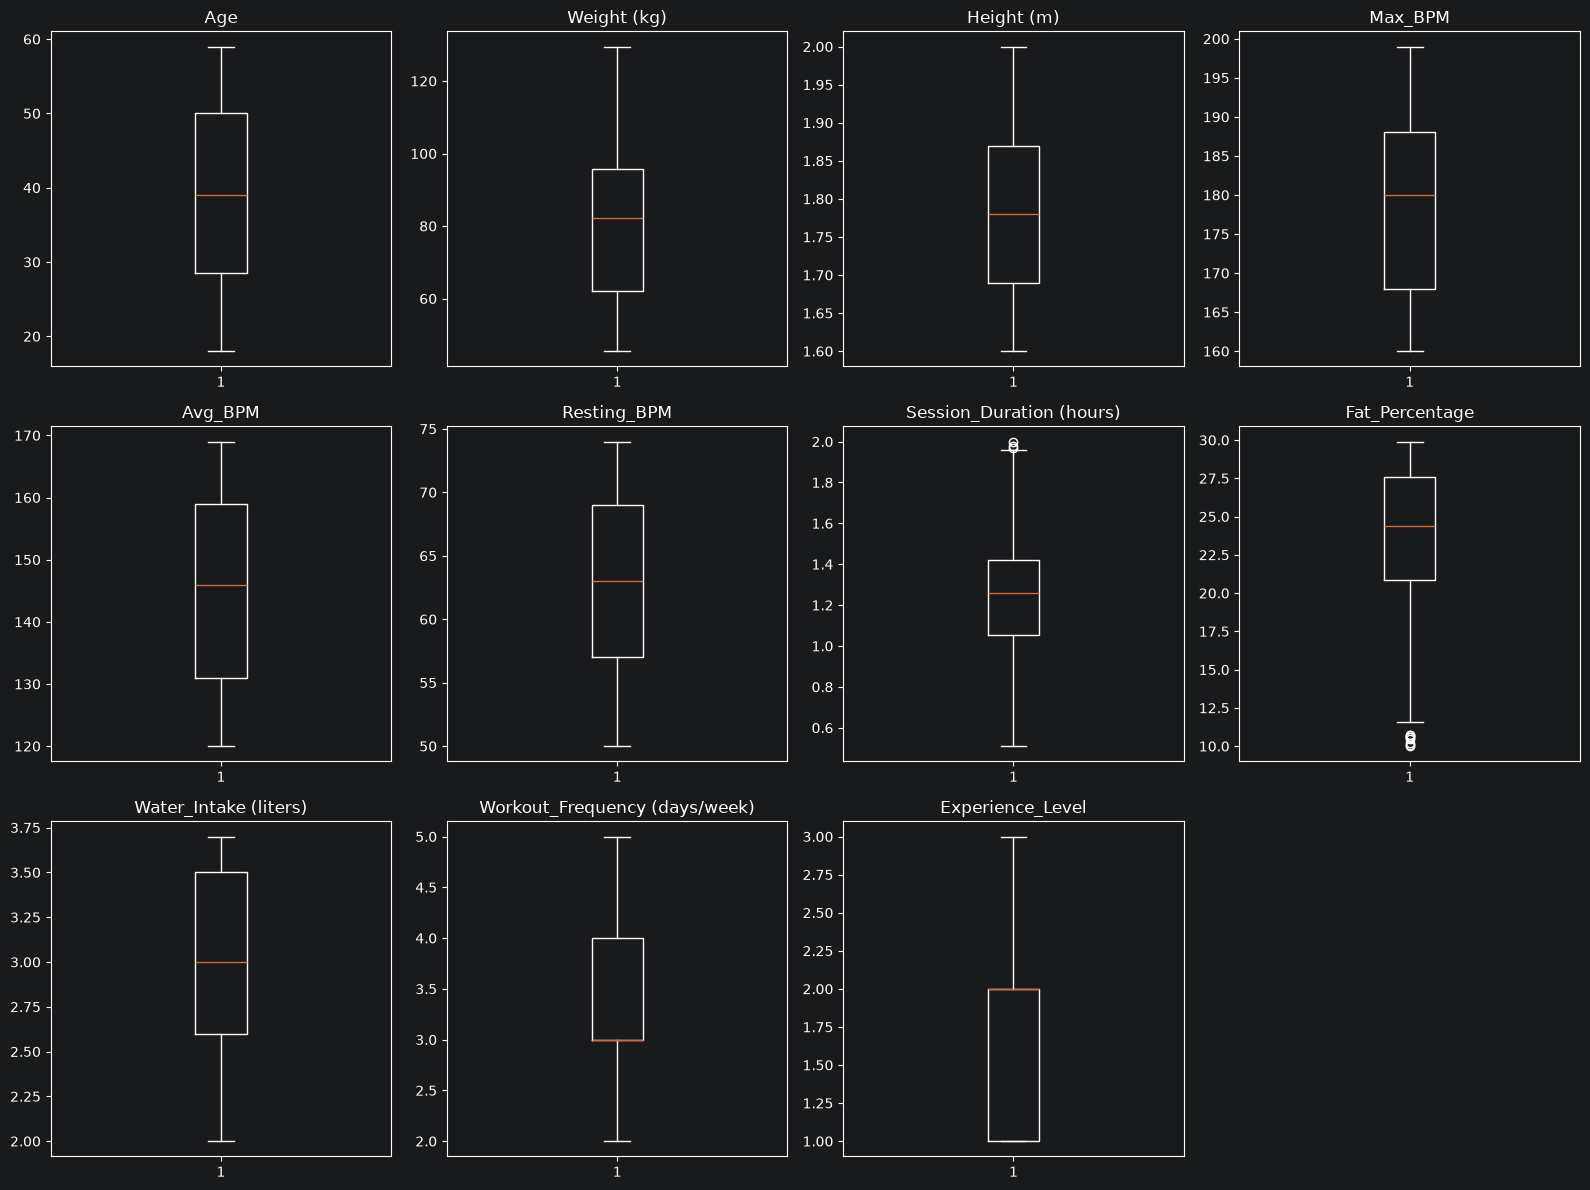

In [91]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

axes = axes.flatten()

for i, feature in enumerate(features):
    axes[i].boxplot(male_strength[feature])
    axes[i].set_title(feature)

# Sakrij višak subplot-a
for i in range(len(features), len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [92]:
#VIDIMO DA IMA OUTLIERI KOD SESSION DURATION (GORNJI) I FAT PERCENTRAGE (DONJI)

In [93]:
Q1 = male_strength['Session_Duration (hours)'].quantile(0.25)
Q3 = male_strength['Session_Duration (hours)'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_session = male_strength[
    (male_strength['Session_Duration (hours)'] < lower_bound) |
    (male_strength['Session_Duration (hours)'] > upper_bound)
]

print("Granice:", lower_bound, upper_bound)
print("Broj outliera:", len(outliers_session))
print(outliers_session['Session_Duration (hours)'].sort_values().to_string(index=False))

Granice: 0.5075000000000005 1.9674999999999996
Broj outliera: 3
1.97
1.98
2.00


In [94]:
from scipy.stats.mstats import winsorize

male_strength = male_strength.copy()

male_strength['Session_Duration (hours)'] = winsorize(
    male_strength['Session_Duration (hours)'],
    limits=[0, 0.04]
)
import matplotlib.pyplot as plt

male_strength['Fat_Percentage'] = winsorize(
    male_strength['Fat_Percentage'],
    limits=[0.06, 0]
)



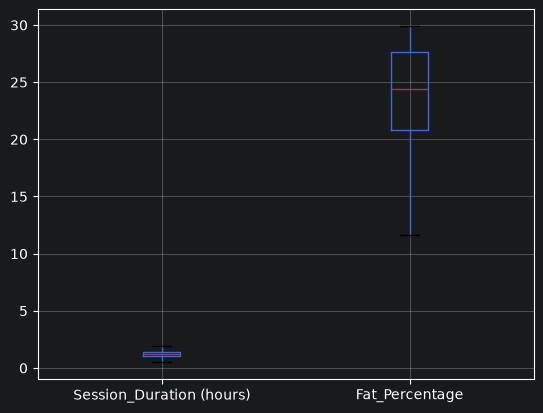

In [95]:
import matplotlib.pyplot as plt

male_strength[
    ['Session_Duration (hours)', 'Fat_Percentage']
].boxplot()

plt.show()

In [96]:
#Za 0.04 gornju grnaicu session duration nema vise outliera,a za 0.06 donju granicu fat percentage nema vise outliera

In [97]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X = male_strength[features]
X_scaled = scaler.fit_transform(X)

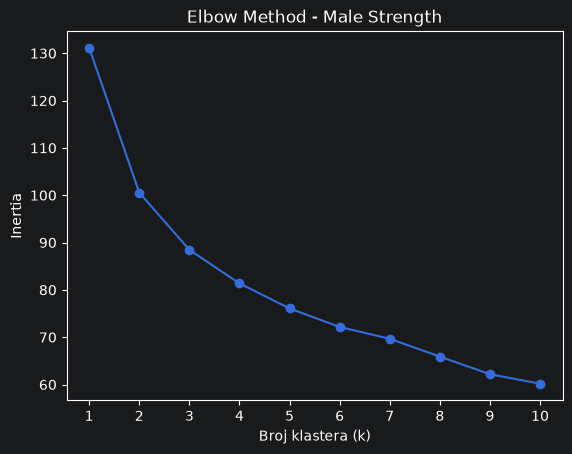

[131.16770547336185,
 100.5525843062501,
 88.4601943178561,
 81.37281957841641,
 76.07034457760761,
 72.1699731921832,
 69.66427076699776,
 65.90152754473134,
 62.17514463090795,
 60.17566859964681]

In [98]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []

K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.plot(K, inertias, marker='o')
plt.xlabel('Broj klastera (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method - Male Strength')
plt.xticks(K)
plt.show()
inertias

k=2: 0.2751
k=3: 0.1605
k=4: 0.1445
k=5: 0.1565
k=6: 0.1465
k=7: 0.1408
k=8: 0.1385
k=9: 0.1298
k=10: 0.1300


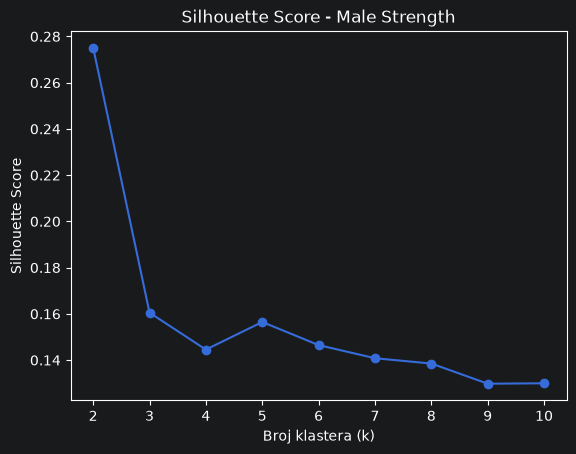

In [99]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"k={k}: {score:.4f}")

plt.plot(K, silhouette_scores, marker='o')
plt.xlabel('Broj klastera (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score - Male Strength')
plt.xticks(K)
plt.show()

In [100]:
#Iz inertia i silhouette score vidimo da su najmerodavniji k=2, za k=3 pa dalje nemamo razlog proveravati

In [126]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

male_strength['Cluster'] = kmeans.fit_predict(X_scaled)

In [127]:
male_strength['Cluster'].value_counts().sort_index()

Cluster
0    112
1     23
Name: count, dtype: int64

In [128]:
male_strength.groupby('Cluster')[features].mean().round(2)

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week)
Cluster,,,,,,,,,,
0,39.86,81.34,1.78,178.54,144.46,63.15,1.14,25.22,2.88,3.13
1,35.70,85.53,1.80,181.35,149.52,61.83,1.78,12.70,3.50,4.61


In [101]:
#Mozemo videti da se u klaster 2 nalaze muskarci malo mladji,malo vece tezine koji imaju duze treninge i cesce i imaju znatno nizi fat percentage od prvog klastera

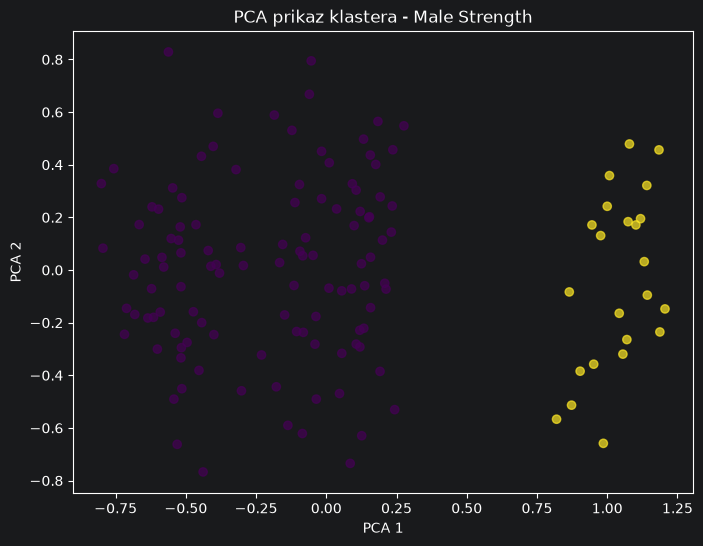

In [129]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=male_strength['Cluster'],
    alpha=0.7
)

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('PCA prikaz klastera - Male Strength')

plt.show()

In [130]:
print("Explained variance ratio:", pca.explained_variance_ratio_)
print(
    "Ukupno objašnjena varijansa:",
    pca.explained_variance_ratio_.sum()
)

Explained variance ratio: [0.31329013 0.11604104]
Ukupno objašnjena varijansa: 0.42933117008136956


In [ ]:
#zajedno ove komponente objasnjavaju 43% varijanse i pca prikazuje vizuelnu strukturu klastera

In [131]:
male_strength.groupby('Cluster')['Calories_Burned'].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

,count,mean,median,std
Cluster,,,,
0,112,857.36,894.0,222.30
1,23,1425.00,1404.0,199.39


In [ ]:
#Utreniraniji klaster trosi oko 600 kalorija vise sto je ocekivano i imamo smislen rezultat
#Sledece idemo na female strengh gde cemo uraditi isti sablon

In [132]:
female_strength = df[
    (df['Gender'] == 'Female') &
    (df['Workout_Type'] == 'Strength')
].copy()

print(female_strength.shape)

(123, 15)


In [133]:
X_female_strength = female_strength[features]

In [134]:
corr_matrix = X_female_strength.corr()
corr_matrix

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week)
Age,1.000000,-0.103662,0.072455,-0.067158,0.053819,-0.003873,0.043264,0.007710,0.109423,-0.028921
Weight (kg),-0.103662,1.000000,-0.052204,0.138472,0.109345,-0.087453,-0.060009,0.087556,-0.071629,0.013035
Height (m),0.072455,-0.052204,1.000000,-0.210017,-0.029064,0.017345,-0.083288,0.108506,-0.042310,-0.075218
Max_BPM,-0.067158,0.138472,-0.210017,1.000000,-0.137013,0.054714,-0.048262,-0.039094,0.024466,0.051976
Avg_BPM,0.053819,0.109345,-0.029064,-0.137013,1.000000,0.099547,-0.249862,0.271739,-0.198200,-0.099994
Resting_BPM,-0.003873,-0.087453,0.017345,0.054714,0.099547,1.000000,-0.128464,0.006502,0.027641,0.008062
Session_Duration (hours),0.043264,-0.060009,-0.083288,-0.048262,-0.249862,-0.128464,1.000000,-0.616377,0.421409,0.581267
Fat_Percentage,0.007710,0.087556,0.108506,-0.039094,0.271739,0.006502,-0.616377,1.000000,-0.485912,-0.585509
Water_Intake (liters),0.109423,-0.071629,-0.042310,0.024466,-0.198200,0.027641,0.421409,-0.485912,1.000000,0.428918
Workout_Frequency (days/week),-0.028921,0.013035,-0.075218,0.051976,-0.099994,0.008062,0.581267,-0.585509,0.428918,1.000000


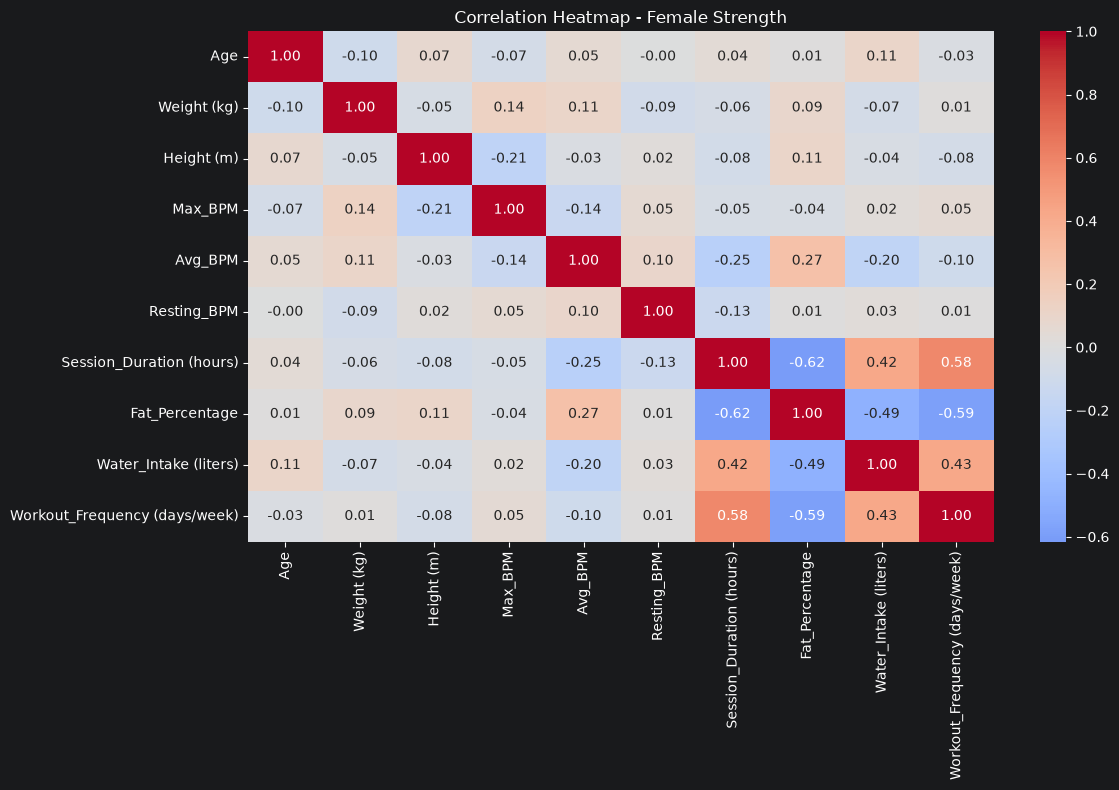

In [135]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = X_female_strength.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap - Female Strength')
plt.tight_layout()
plt.show()

In [ ]:
#Nema niste preko 0.7 pa ne izabacujemo nista

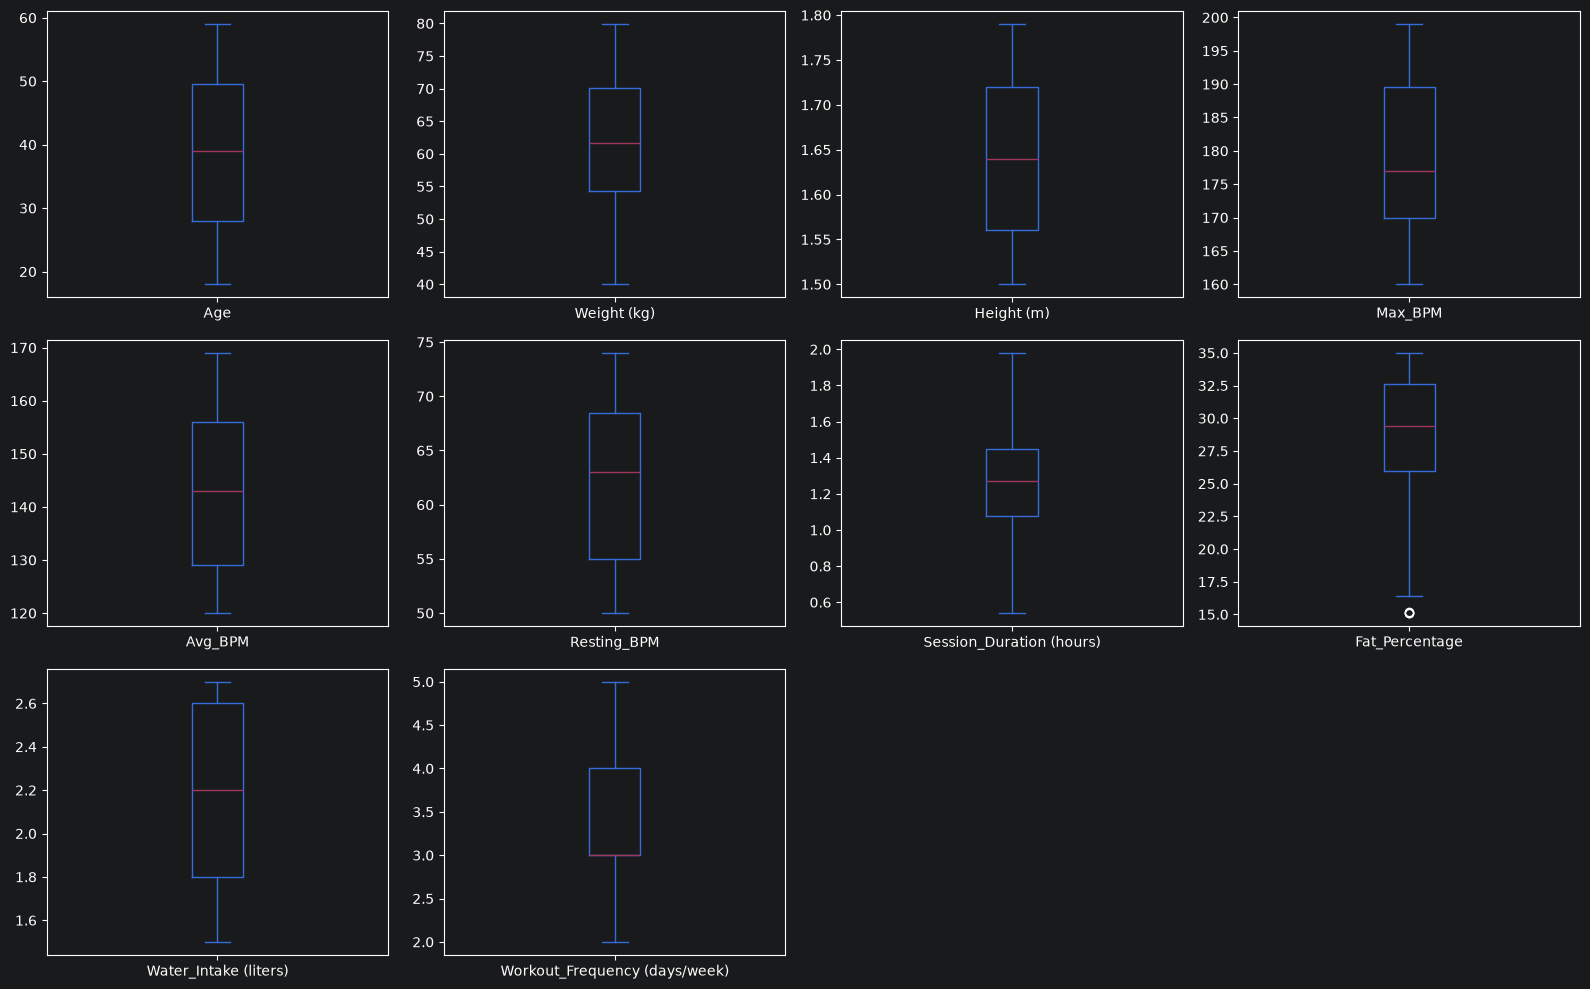

In [136]:
import matplotlib.pyplot as plt

X_female_strength.plot(
    kind='box',
    subplots=True,
    layout=(3, 4),
    figsize=(16, 10),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

In [140]:
from scipy.stats.mstats import winsorize

female_strength['Fat_Percentage'] = winsorize(
    female_strength['Fat_Percentage'],
    limits=[0.03, 0]
)
X_female_strength = female_strength[features]

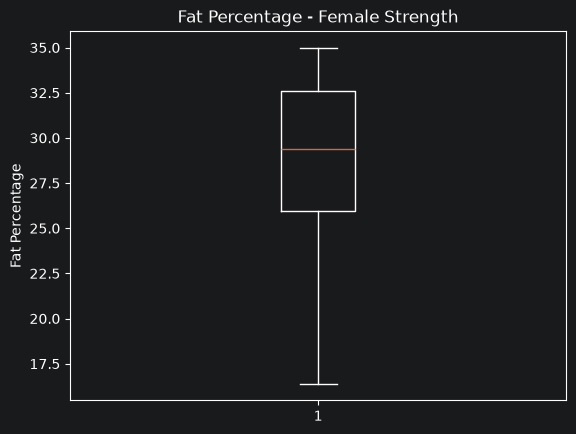

In [141]:
plt.boxplot(X_female_strength['Fat_Percentage'])
plt.ylabel('Fat Percentage')
plt.title('Fat Percentage - Female Strength')
plt.show()

In [102]:
#ceo dataset je dole,gore ono sa 4 dataseta

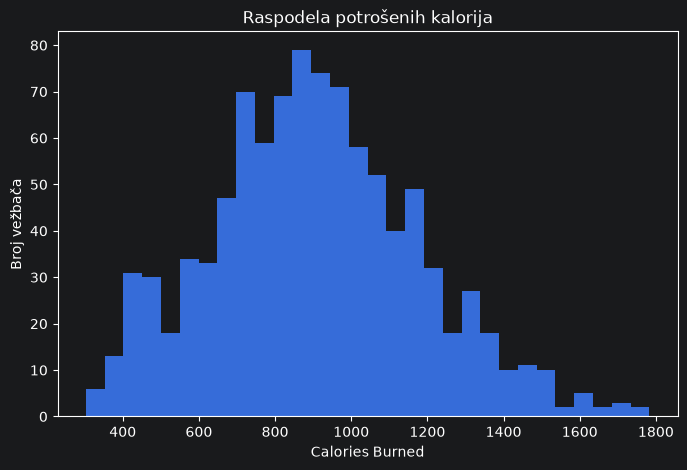

In [103]:
plt.figure(figsize=(8, 5))

plt.hist(df["Calories_Burned"], bins=30)

plt.xlabel("Calories Burned")
plt.ylabel("Broj vežbača")
plt.title("Raspodela potrošenih kalorija")

plt.show()

In [104]:
df[["Calories_Burned", "Session_Duration (hours)"]].corr()

,Calories_Burned,Session_Duration (hours)
Calories_Burned,1.00000,0.90814
Session_Duration (hours),0.90814,1.00000


In [105]:
df[["Calories_Burned", "Avg_BPM", "Weight (kg)",
    "Session_Duration (hours)"]].corr()

,Calories_Burned,Avg_BPM,Weight (kg),Session_Duration (hours)
Calories_Burned,1.000000,0.339659,0.095443,0.908140
Avg_BPM,0.339659,1.000000,0.009717,0.016014
Weight (kg),0.095443,0.009717,1.000000,-0.013666
Session_Duration (hours),0.908140,0.016014,-0.013666,1.000000


In [106]:
1.000000,0.339659,0.095443,0.908140
0.339659,1.000000,0.009717,0.016014
0.095443,0.009717,1.000000,-0.013666
0.908140,0.016014,-0.013666,1.000000


(0.90814, 0.016014, -0.013666, 1.0)

In [107]:
features = [
    'Age',
    'Weight (kg)',
    'Height (m)',
    'Max_BPM',
    'Avg_BPM',
    'Resting_BPM',
    'Session_Duration (hours)',
    'Fat_Percentage',
    'Water_Intake (liters)',
    'Workout_Frequency (days/week)',
    'Experience_Level'
]

X = df[features].copy()

#Ostavljamo BMI van features jer je izveden iz height i weight
#Calories burned isto ne jer zelimo posle da vidimo vrednosti po klasterima

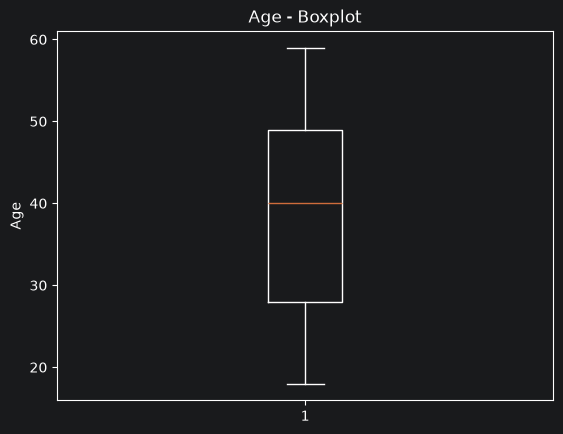

count    973.000000
mean      38.683453
std       12.180928
min       18.000000
25%       28.000000
50%       40.000000
75%       49.000000
max       59.000000
Name: Age, dtype: float64

In [108]:
from scipy.stats.mstats import winsorize

#gledanje svakog atributa za outliere

import matplotlib.pyplot as plt

plt.boxplot(df['Age'])
plt.title('Age - Boxplot')
plt.ylabel('Age')
plt.show()

df['Age'].describe()


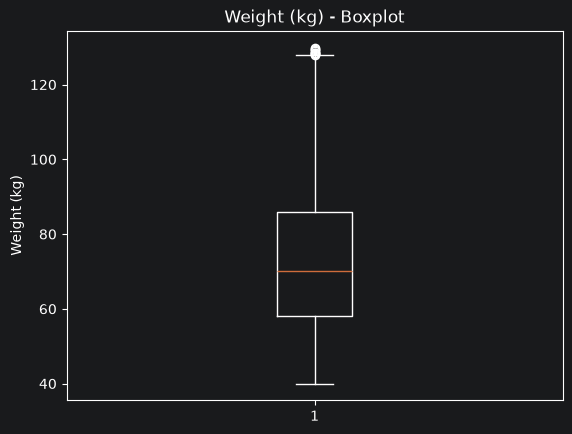

count    973.000000
mean      73.854676
std       21.207500
min       40.000000
25%       58.100000
50%       70.000000
75%       86.000000
max      129.900000
Name: Weight (kg), dtype: float64

In [109]:
plt.boxplot(df['Weight (kg)'])
plt.title('Weight (kg) - Boxplot')
plt.ylabel('Weight (kg)')
plt.show()

df['Weight (kg)'].describe()

In [110]:
Q1 = df['Weight (kg)'].quantile(0.25)
Q3 = df['Weight (kg)'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("donja granica:",lower)
print("gornja granica:",upper)

outliers = df[(df['Weight (kg)'] < lower) | (df['Weight (kg)'] > upper)]

print("Broj autlajera:",len(outliers))
print(outliers['Weight (kg)'].sort_values())








donja granica: 16.250000000000007
gornja granica: 127.85
Broj autlajera: 9
648    127.9
180    128.2
291    128.4
283    128.4
614    128.4
96     129.0
854    129.2
122    129.5
593    129.9
Name: Weight (kg), dtype: float64


In [111]:
weight_outliers = df[df['Weight (kg)'] > 127.85]

print("Broj outliera:", len(weight_outliers))
print(weight_outliers['Weight (kg)'].sort_values())

Broj outliera: 9
648    127.9
180    128.2
291    128.4
283    128.4
614    128.4
96     129.0
854    129.2
122    129.5
593    129.9
Name: Weight (kg), dtype: float64


In [112]:
from scipy.stats.mstats import winsorize
#otklanjamo gornje outliere


df['Weight (kg)'] = winsorize(
    df['Weight (kg)'],
    limits=[0, 0.01]
)

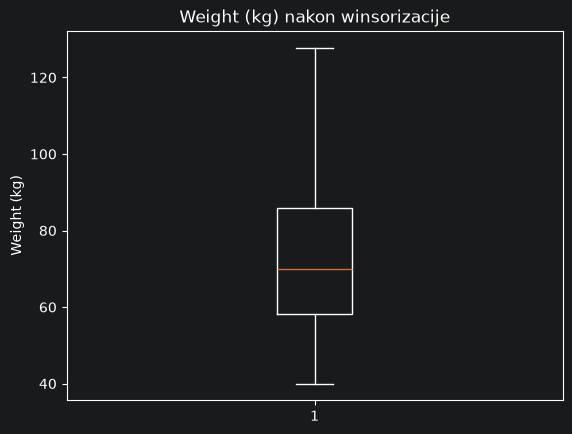

/Users/brankomitic/DataspellProjects/alternativni_dataset_diplomski/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4798: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


count    973.000000
mean      73.845735
std       21.184429
min       40.000000
25%       58.100000
50%       70.000000
75%       86.000000
max      127.800000
Name: Weight (kg), dtype: float64

In [113]:
plt.boxplot(df['Weight (kg)'])
plt.title('Weight (kg) nakon winsorizacije')
plt.ylabel('Weight (kg)')
plt.show()

df['Weight (kg)'].describe()

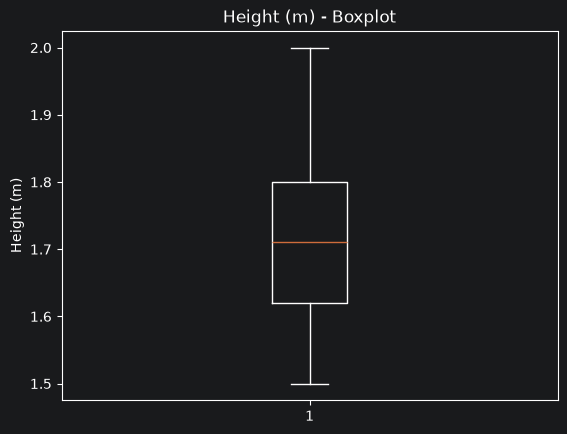

count    973.00000
mean       1.72258
std        0.12772
min        1.50000
25%        1.62000
50%        1.71000
75%        1.80000
max        2.00000
Name: Height (m), dtype: float64

In [114]:
plt.boxplot(df['Height (m)'])
plt.title('Height (m) - Boxplot')
plt.ylabel('Height (m)')
plt.show()

df['Height (m)'].describe()

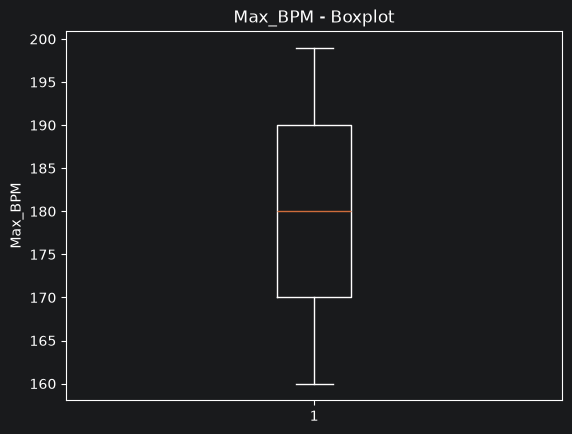

count    973.000000
mean     179.883864
std       11.525686
min      160.000000
25%      170.000000
50%      180.000000
75%      190.000000
max      199.000000
Name: Max_BPM, dtype: float64

In [115]:
plt.boxplot(df['Max_BPM'])
plt.title('Max_BPM - Boxplot')
plt.ylabel('Max_BPM')
plt.show()

df['Max_BPM'].describe()

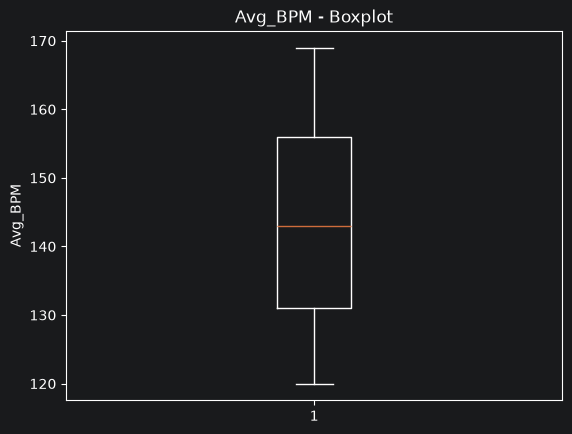

In [116]:
plt.boxplot(df['Avg_BPM'])
plt.title('Avg_BPM - Boxplot')
plt.ylabel('Avg_BPM')
plt.show()

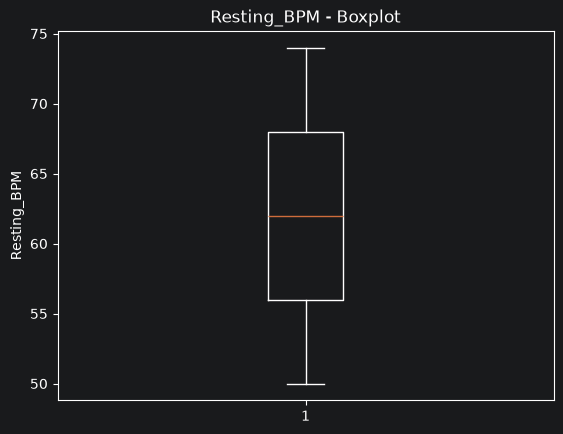

count    973.000000
mean      62.223022
std        7.327060
min       50.000000
25%       56.000000
50%       62.000000
75%       68.000000
max       74.000000
Name: Resting_BPM, dtype: float64

In [117]:
plt.boxplot(df['Resting_BPM'])
plt.title('Resting_BPM - Boxplot')
plt.ylabel('Resting_BPM')
plt.show()

df['Resting_BPM'].describe()

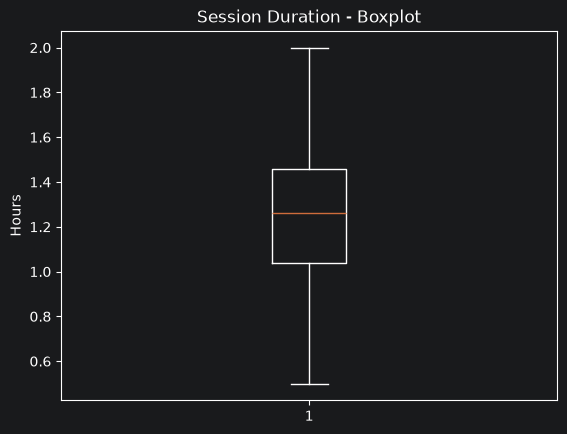

count    973.000000
mean       1.256423
std        0.343033
min        0.500000
25%        1.040000
50%        1.260000
75%        1.460000
max        2.000000
Name: Session_Duration (hours), dtype: float64

In [118]:
plt.boxplot(df['Session_Duration (hours)'])
plt.title('Session Duration - Boxplot')
plt.ylabel('Hours')
plt.show()

df['Session_Duration (hours)'].describe()

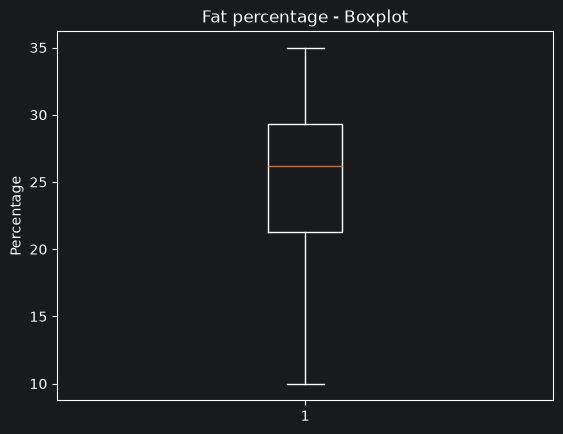

In [119]:
plt.boxplot(df['Fat_Percentage'])
plt.title("Fat percentage - Boxplot")
plt.ylabel('Percentage')
plt.show()

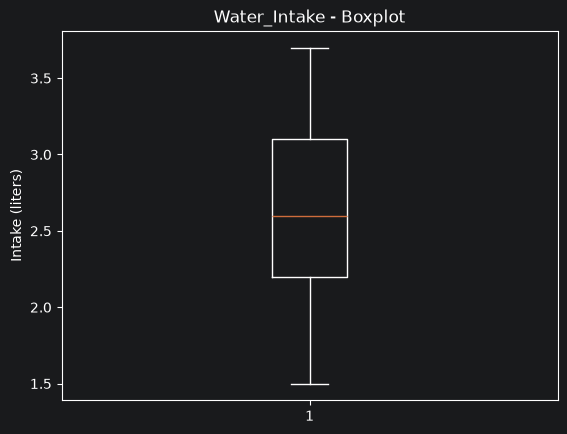

In [120]:
plt.boxplot(df['Water_Intake (liters)'])
plt.title("Water_Intake - Boxplot")
plt.ylabel('Intake (liters)')
plt.show()

In [121]:
print(df['Workout_Frequency (days/week)'].value_counts().sort_index())
print()
print(df['Experience_Level'].value_counts().sort_index())

Workout_Frequency (days/week)
2    197
3    368
4    306
5    102
Name: count, dtype: int64

Experience_Level
1    376
2    406
3    191
Name: count, dtype: int64


In [122]:
numeric_df = df.select_dtypes(include='number')

correlation_matrix = numeric_df.corr()

print(correlation_matrix)



                                    Age  Weight (kg)  Height (m)   Max_BPM  \
Age                            1.000000    -0.036699   -0.027837 -0.017073   
Weight (kg)                   -0.036699     1.000000    0.365507  0.057133   
Height (m)                    -0.027837     0.365507    1.000000 -0.017660   
Max_BPM                       -0.017073     0.057133   -0.017660  1.000000   
Avg_BPM                        0.035969     0.009628   -0.014776 -0.039751   
Resting_BPM                    0.004354    -0.032164   -0.005090  0.036647   
Session_Duration (hours)      -0.019912    -0.013313   -0.010206  0.010051   
Calories_Burned               -0.154679     0.095854    0.086348  0.002090   
Fat_Percentage                 0.002370    -0.225667   -0.235521 -0.009056   
Water_Intake (liters)          0.041528     0.394473    0.393533  0.031621   
Workout_Frequency (days/week)  0.008055    -0.011591   -0.011270 -0.029099   
Experience_Level              -0.018676     0.003668   -0.010267

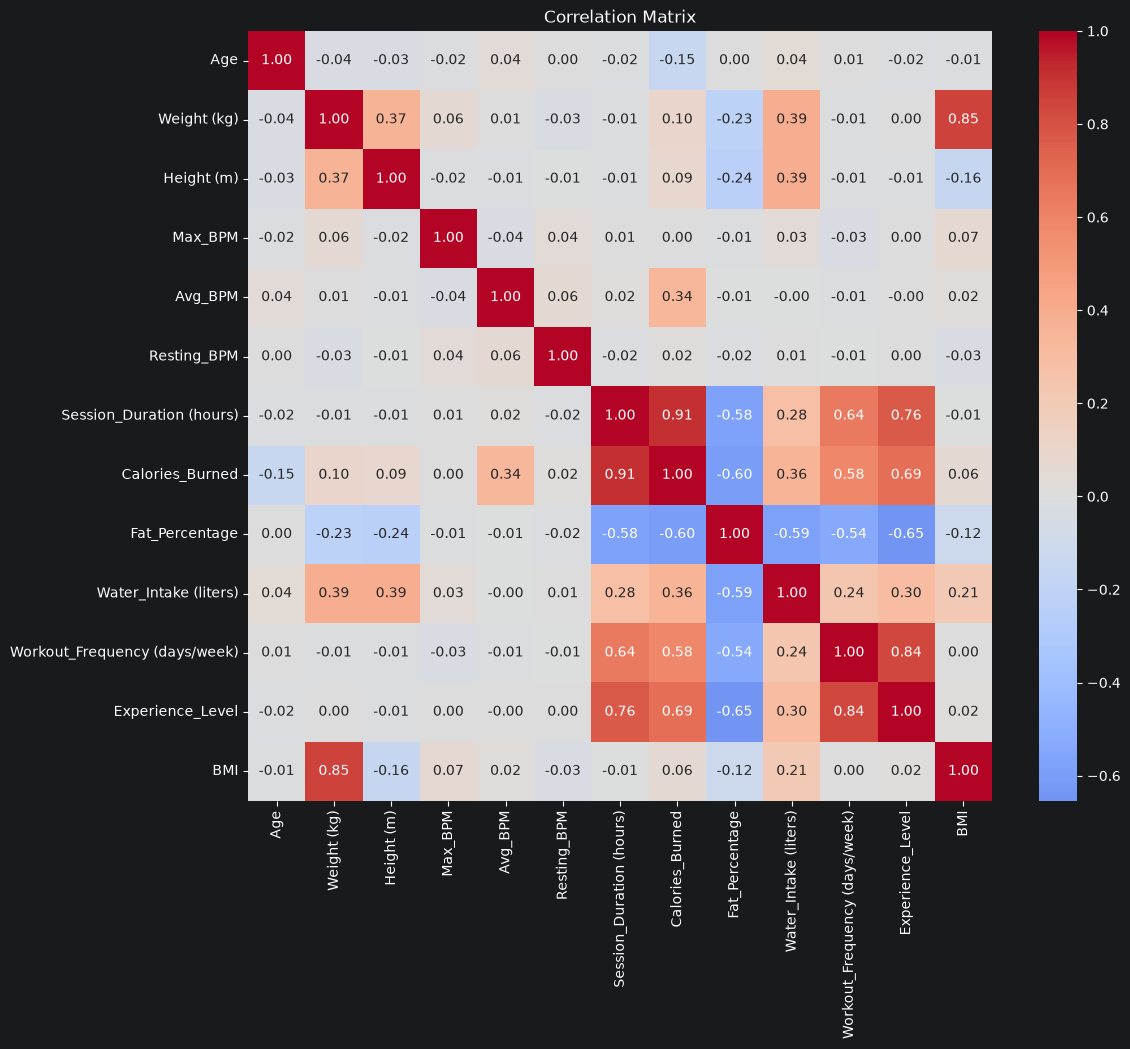

In [123]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))

sb.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Matrix')
plt.show()

In [124]:
#Izbacujemo expereince level, on ima visoku korelaciju sa dva atributa pa je najalkse njega izbaciti

In [125]:
features = [
    'Age',
    'Weight (kg)',
    'Height (m)',
    'Max_BPM',
    'Avg_BPM',
    'Resting_BPM',
    'Session_Duration (hours)',
    'Fat_Percentage',
    'Water_Intake (liters)',
    'Workout_Frequency (days/week)'
]

X = df[features].copy()